## identify inactive subreddits and make URL requests to check their status

without any external list of (political) subreddits


<img src="../../../notes/flowchart-identify-banned-subreddits-new.png" alt="flowchart" width="750"/>


In [1]:
import pandas as pd
import numpy as np
import json
import glob
import os 

from collections import Counter
import matplotlib.pyplot as plt
import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats("retina")

### load summaries of activity level from the remote pipeline

- get the number of submission/comment counts per submission per year from the server
- let's say we focus on subreddits banned in 2020 --> the year of Reddit great ban

In [2]:
year = 2020
count_dir = "../../../data/counts"
active_df = pd.read_csv(f"{count_dir}/n_submissions_author_min_utc_per_subreddit_{year}.csv")
active_df = active_df[~active_df["subreddit"].str.startswith("u_", na=False)]

active_df2 = pd.DataFrame()
for y in range(year+1, 2023):
    print(y)
    # df = pd.read_csv(f"{count_dir}/n_submissions_author_min_utc_per_subreddit_{year+1}.csv") # this is a mistake!
    df = pd.read_csv(f"{count_dir}/n_submissions_author_min_utc_per_subreddit_{y}.csv")
    active_df2 = pd.concat([df, active_df2])

active_df2 = active_df2[~active_df2["subreddit"].str.startswith("u_", na=False)]

2021
2022


In [ ]:
print(f"# of active subreddits in {year}:", len(active_df))

# of active subreddits in 2020: 916537


### find out inactive subreddits in Y

- have some activity in Y 
- do not have any activity from Y+1 to 2022

In [8]:
activity_thres = 10
author_thres = 5

active_df_filter = active_df[(active_df["n_subm"]>=activity_thres)&(active_df["n_subm_author"]>=author_thres)]
print(f"# of active subreddits in {year} (after filtering):", len(active_df_filter))

inactive_subrs = set(active_df_filter["subreddit"].tolist()) - set(active_df2["subreddit"].tolist())
print("# of inactive subreddits:", len(inactive_subrs))

# 2020
# # of inactive subreddits: 12719 for activity_thres = 10 and author_thres = 10
# # of inactive subreddits: 23994 for activity_thres = 10 and author_thres = 5 --> currently using!

# 2019
# # of inactive subreddits: 17924 for activity_thres = 10 and author_thres = 5
# 2016
# # of inactive subreddits: 13592 for activity_thres = 10 and author_thres = 5

# of active subreddits in 2020 (after filtering): 175480
# of inactive subreddits: 21594


### make URL requests to check the subreddit status

In [4]:
subr_ls = list(inactive_subrs)
print("# of subreddits to check:", len(subr_ls))
# output_fname = "../../../index/inactive_subreddits_status_251001.json"                # --> 2020 banned subreddits
output_fname = f"../../../index/inactive_subreddits_status_{year}_251125.json"       # --> 2015-2019 banned subreddits

# of subreddits to check: 4868


In [5]:
# the same with 250915b-crawl-banning-reason.ipynb
# 1st round: going through all the subreddits 
# look up the saved subreddits and start with the remaining ones
 
# if os.path.exists(output_fname):
#     with open(output_fname, "r", encoding="utf-8") as jsonf:
#         subr_checked = json.load(jsonf)
#     subr_ls2 = list(set(subr_ls) - set(subr_checked.keys()))
# else:
#     subr_checked = {}
#     subr_ls2 = subr_ls
# print("number of subreddits checked:", len(subr_checked))
# print("number of subreddits to be checked:", len(subr_ls2))

In [6]:
# # 2nd round: check timeout cases (with empty output) and re-check those subreddits

# with open(output_fname, "r", encoding="utf-8") as jsonf:
#     subr_checked = json.load(jsonf)
# subr_ls2 = {k for k,msg in subr_checked.items() if msg==""}
# print("number of subreddits to be re-checked:", len(subr_ls2))

In [7]:
from src.utils.label_subreddit import check_subreddit_status

# uncomment the code lines below if I actually want to make the URL requests
# batch_size = 800
# output = check_subreddit_status(subr_ls2[:batch_size])
# for a batch of 800 this may take 33 mins

# or do the entire set
# output = check_subreddit_status(list(subr_ls2))

In [8]:
# subr_checked.update(output)  # appending to saved output
# with open(output_fname, "w", encoding="utf-8") as jsonf:
#     json.dump(subr_checked, jsonf, indent=4) 

In [9]:
# len(subr_checked)

### clean banned list

In [10]:
with open(output_fname, "r", encoding="utf-8") as jsonf:
    data = json.load(jsonf)
df = pd.DataFrame([data]).T.reset_index()
df.columns = ["subreddit", "full_msg"]
df["full_msg"] = df["full_msg"].map(lambda x: x.lower().strip())
df.head()

,subreddit,full_msg
0,xcrafters,reddit - the heart of the internet skip to mai...
1,aeries,reddit - the heart of the internet skip to mai...
2,planpsyexperiences,reddit - the heart of the internet skip to mai...
3,cultofzezima,reddit - the heart of the internet skip to mai...
4,vaibondhu,reddit - the heart of the internet skip to mai...


In [11]:
from src.utils.label_subreddit import clean, check_status_from_message
from src.utils.label_subreddit import MANUL_CORRECT_MAP

df["clean_msg"] = df.apply(lambda x: clean(x.full_msg, x.subreddit), axis=1)
df["status"] = df["clean_msg"].map(lambda x: check_status_from_message(x))
df.head()

,subreddit,full_msg,clean_msg,status
0,xcrafters,reddit - the heart of the internet skip to mai...,r/log in log in to reddit expand user menu ope...,quiet
1,aeries,reddit - the heart of the internet skip to mai...,r/log in log in to reddit expand user menu ope...,quiet
2,planpsyexperiences,reddit - the heart of the internet skip to mai...,r/log in log in to reddit expand user menu ope...,quiet
3,cultofzezima,reddit - the heart of the internet skip to mai...,r/log in log in to reddit expand user menu ope...,quiet
4,vaibondhu,reddit - the heart of the internet skip to mai...,r/log in log in to reddit expand user menu ope...,quiet


In [12]:
df.loc[df["subreddit"].isin(MANUL_CORRECT_MAP.keys()), "status"] = (
    df["subreddit"].map(MANUL_CORRECT_MAP)
)

# correct subreddit status that I have checked manually

In [13]:
notbanned_df = df[df["status"]!="banned"]
print("# of not-banned subreddits:", len(notbanned_df))
# notbanned_df.to_csv("../../../index/not_banned_251003.csv", index=False)

# of not-banned subreddits: 4073


In [ ]:
print("# of banned subreddits:",len(df[df["status"]=="banned"]))
# 2019: 6590
# 2018: 4156
# 2017: 1906
# 2016: 3603
# 2015: 795

# of banned subreddits: 795


       status  count
3       empty     65
2  restricted    498
4     private    532
1      banned    795
0       quiet   2978


Text(0.5, 1.0, 'count of subreddits in each status')

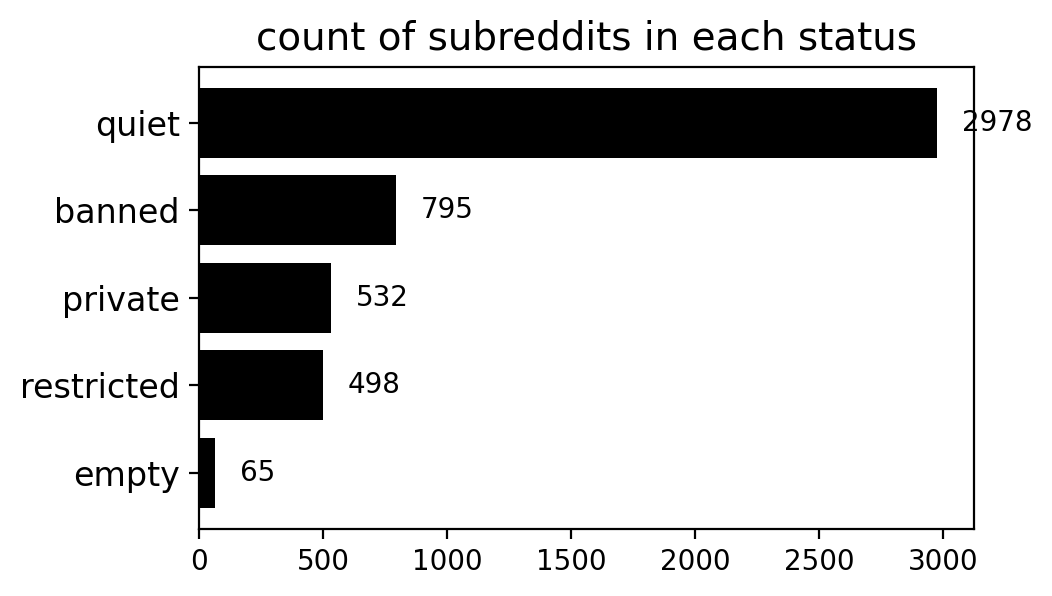

In [15]:
# some descriptives
counts = Counter(df["status"].tolist())
counts_df = pd.DataFrame()
counts_df["status"] = counts.keys()
counts_df["count"] = counts.values()
counts_df.sort_values(by="count", ascending=True, inplace=True)
print(counts_df)

fig,ax = plt.subplots(figsize=(5,3))
plt.barh([x.replace("_", " ") for x in counts_df["status"]], counts_df["count"], color="black")
plt.yticks(fontsize=12)
for i, v in enumerate(counts_df["count"]):
    plt.text(v+100, i, str(v), va="center")  # v + offset, i = y-position
plt.title("count of subreddits in each status", fontsize=14)
# plt.savefig("../../../output/251003-output/subreddit-count-per-status.png", dpi=300, bbox_inches="tight")

In [16]:
df.to_csv(f"../../../index/inactive_subreddits_status_self_identify_{year}_251125.csv", index=False)

In [ ]:
banned_df = df[df["status"]=="banned"].copy()
print(len(banned_df))
banned_df.head()

6590


,subreddit,full_msg,clean_msg,status
0,samanthasaintnsfw,reddit - the heart of the internet skip to mai...,r/r/ is banned this subreddit was banned due t...,banned
1,escortencounters,reddit - the heart of the internet skip to mai...,r/r/ is banned this subreddit was banned due t...,banned
7,collegebabejobuds,reddit - the heart of the internet skip to mai...,r/r/ is banned this subreddit was banned due t...,banned
8,ratemynips,reddit - the heart of the internet skip to mai...,r/r/ is banned this subreddit was banned due t...,banned
9,the_richter,reddit - the heart of the internet skip to mai...,r/r/ is banned this subreddit was banned due t...,banned


In [ ]:
from src.utils.label_subreddit import extract_reason

banned_df["reason"] = banned_df["clean_msg"].map(lambda x: extract_reason(x))

In [ ]:
reason_counter = dict(Counter(banned_df["reason"].tolist()))
counter_df = pd.DataFrame([reason_counter]).T.reset_index()
counter_df.columns = ["reason","count"]
counter_df["reason"] = counter_df["reason"].map(lambda x: x.replace("_", " "))
counter_df = counter_df.sort_values(by="count")
# counter_df

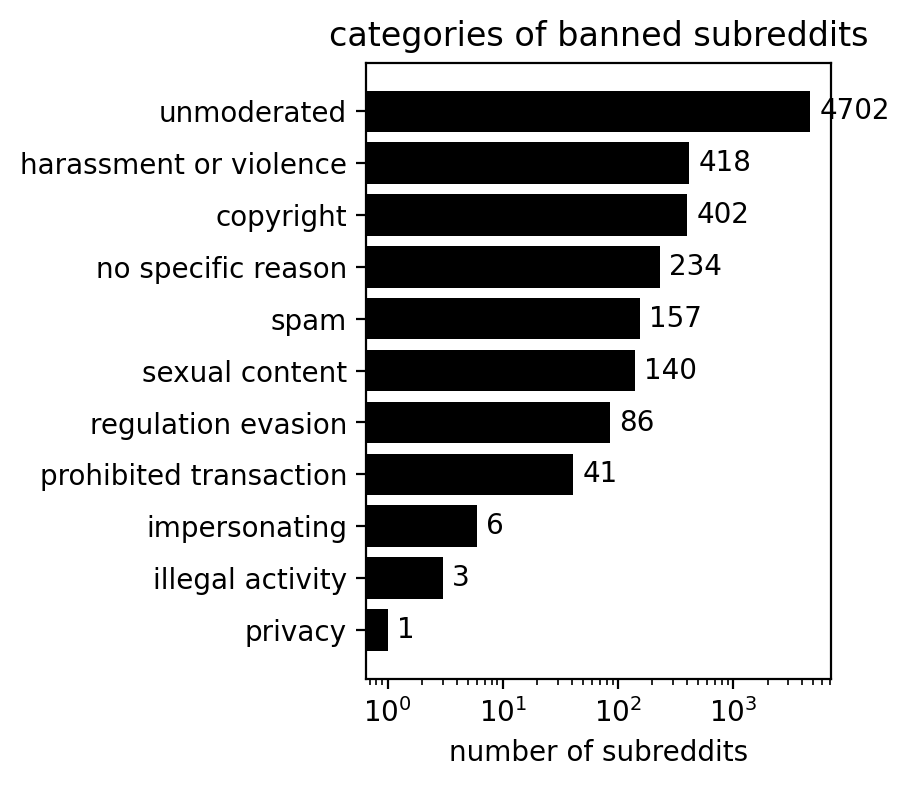

In [ ]:
fig,ax = plt.subplots(figsize=(3,4))
plt.barh(counter_df["reason"], counter_df["count"], color="black")
for i, v in enumerate(counter_df["count"]):
    plt.text(v*1.2, i, str(v), va="center")  # v + offset, i = y-position
plt.xlabel("number of subreddits")
plt.title("categories of banned subreddits", fontsize=12)
plt.xscale("log")
plt.savefig("../../../output/251003-output/ban_categories.png", dpi=300, bbox_inches="tight")

In [ ]:
# banned_df[["subreddit","reason"]].to_csv("../../../index/banned_subreddits_cleaned_251006.csv", index=False)